In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv("melon.csv")
df = pd.DataFrame(data)
df

,Weight,Price
0,1,50
1,2,100
2,3,140
3,4,180
4,5,220
5,6,250
6,7,300
7,8,340
8,9,380
9,10,390


In [3]:
df.shape

(10, 2)

In [4]:
df.columns

Index(['Weight', 'Price'], dtype='str')

In [5]:
df.head()

,Weight,Price
0,1,50
1,2,100
2,3,140
3,4,180
4,5,220


In [6]:
df.describe(include="all")

,Weight,Price
count,10.00000,10.000000
mean,5.50000,235.000000
std,3.02765,117.968922
min,1.00000,50.000000
25%,3.25000,150.000000
50%,5.50000,235.000000
75%,7.75000,330.000000
max,10.00000,390.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Weight  10 non-null     int64
 1   Price   10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes


In [8]:
df.size

20

In [9]:
df.corr()

,Weight,Price
Weight,1.000000,0.997039
Price,0.997039,1.000000


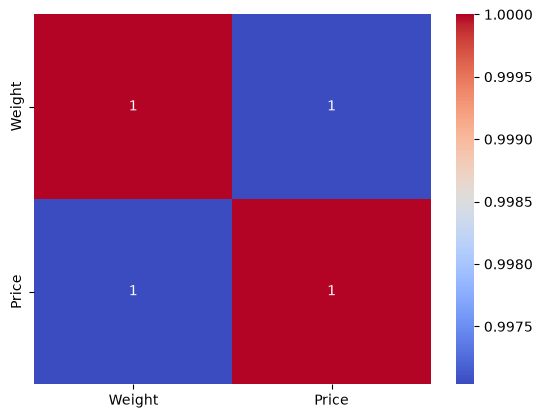

In [10]:
sns.heatmap(df.corr(),annot = True,cmap="coolwarm")
plt.show()

In [11]:
X = df[["Weight"]]
y = df["Price"]


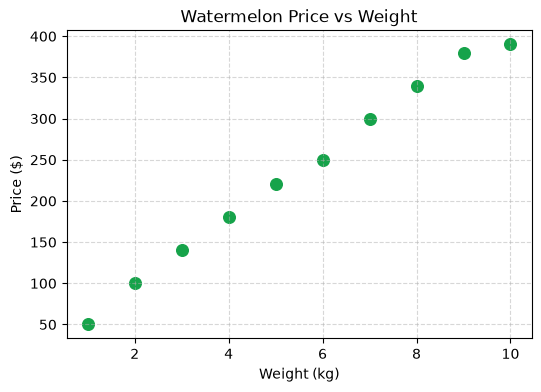

In [12]:
plt.figure(figsize=(6, 4))
plt.scatter(df["Weight"], df["Price"], color="#16a34a", s=70)
plt.xlabel("Weight (kg)")
plt.ylabel("Price ($)")
plt.title("Watermelon Price vs Weight")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


# Train Test Split and Feature Scaling


In [13]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.3,random_state = 42)

In [14]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [15]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_pred

array([368.53960396,  99.8019802 , 253.36633663])

In [16]:
pred_2kg = model.predict(scaler.transform([[2]]))[0]
print(f"Predicted price for 2kg watermelon: ${pred_2kg:.2f}")


Predicted price for 2kg watermelon: $99.80


C:\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred):.2f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")


R2 Score: 0.9964
Mean Absolute Error (MAE): 5.01
Root Mean Squared Error (RMSE): 6.90
